# (vision-language) on Kaggle with Ollama, split over 2 GPUs

**Before running, set these in Kaggle's right-hand panel (Settings):**
1. **Accelerator → GPU T4 x2** (two 16 GB T4 GPUs)
2. **Internet → On** (needed to download Ollama and the model)

Then run the cells from top to bottom.

**How it works:** [Ollama](https://ollama.com) is a small program that downloads a model and runs it as a local server. Python talks to that server through the `ollama` package. By default Ollama puts a model on **one** GPU if it fits there; setting `OLLAMA_SCHED_SPREAD=1` before the server starts makes it **split the model's layers across both GPUs**.

## 1. Check that Kaggle gave us two GPUs

In [10]:
# nvidia-smi lists the GPUs. You should see two "Tesla T4" rows.
# If you see only one (or an error), change Settings -> Accelerator -> GPU T4 x2 and restart the session.
!nvidia-smi --query-gpu=index,name,memory.total,memory.used --format=csv

index, name, memory.total [MiB], memory.used [MiB]
0, Tesla T4, 15360 MiB, 0 MiB
1, Tesla T4, 15360 MiB, 0 MiB


## 2. Install Ollama and the Python client

In [11]:
# zstd is needed to unpack the Ollama download. -qq keeps the output short.
!apt-get update -qq && apt-get install -y -qq zstd > /dev/null

# Official Ollama install script (downloads the ollama program into /usr/local).
# The warnings "systemd is not running" and "Unable to detect NVIDIA/AMD GPU" are normal on Kaggle:
# Kaggle has no systemd, and Ollama finds the GPUs by itself when the server starts.
!curl -fsSL https://ollama.com/install.sh | sh

# Python client for talking to the Ollama server, plus Pillow for images.
!pip install -q ollama pillow requests

W: https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64/InRelease: Key is stored in legacy trusted.gpg keyring (/etc/apt/trusted.gpg), see the DEPRECATION section in apt-key(8) for details.
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
>>> Cleaning up old version at /usr/local/lib/ollama
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%#########################################          89.6%
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


## 3. Start the Ollama server, spread over both GPUs

The settings below are **environment variables**: options the server reads when it starts. They must be set *before* `ollama serve` runs; changing them later has no effect until the server is restarted (re-run this cell).

In [12]:
import os, subprocess, time, requests

# Stop any server left over from a previous run of this cell, so the new settings apply.
subprocess.run(["pkill", "-f", "ollama serve"], stderr=subprocess.DEVNULL)
time.sleep(2)

env = os.environ.copy()
env["CUDA_VISIBLE_DEVICES"] = "0,1"        # let Ollama see both T4 GPUs
env["OLLAMA_SCHED_SPREAD"] = "1"           # KEY SETTING: split the model across all visible GPUs
env["OLLAMA_CONTEXT_LENGTH"] = "8192"      # max tokens per conversation; smaller = less GPU memory (default here was 32768)
env["OLLAMA_KEEP_ALIVE"] = "30m"           # keep the model loaded in GPU memory for 30 min between questions
env["OLLAMA_HOST"] = "127.0.0.1:11434"     # address the server listens on (the Python client uses the same default)

# Start the server in the background. Its (very long) log goes to a file instead of flooding the notebook.
LOG_PATH = "/kaggle/working/ollama.log"
log_file = open(LOG_PATH, "w")
ollama_process = subprocess.Popen(["ollama", "serve"], env=env, stdout=log_file, stderr=subprocess.STDOUT)

# Wait until the server answers, instead of guessing with a fixed sleep.
for _ in range(60):
    try:
        v = requests.get("http://127.0.0.1:11434/api/version", timeout=1).json()
        print("Ollama server is running, version", v["version"])
        break
    except requests.exceptions.RequestException:
        time.sleep(1)
else:
    raise RuntimeError(f"Ollama did not start; look at {LOG_PATH}")

Ollama server is running, version 0.40.3


## 4. Download the model

`qwen3.5:9b` is a 9-billion-parameter model that understands **text and images**. Ollama's default version is quantized to about 4 bits, so the download is about 6.5 GB (5.6 GB of weights plus a 0.9 GB vision part). Other options you can put in `MODEL`: `qwen3.5:4b` (smaller, faster), `qwen3-vl:8b`.

In [13]:
import ollama

MODEL = "qwen3.5:27b" # Modle Name from Ollama

# ollama.pull streams progress messages; we print one line every ~10 % instead of hundreds of lines.
last_shown = -10
for update in ollama.pull(MODEL, stream=True):
    total, done = update.get("total"), update.get("completed")
    if total and done:
        pct = int(100 * done / total)
        if pct >= last_shown + 10:
            print(f"{update['status']}: {pct}%")
            last_shown = pct
    elif update.get("status") in ("verifying sha256 digest", "writing manifest", "success"):
        print(update["status"])
        last_shown = -10   # reset for the next file in the download

pulling 2abfbdeed279: 1%
pulling 2abfbdeed279: 12%
pulling 2abfbdeed279: 23%
pulling 2abfbdeed279: 33%
pulling 2abfbdeed279: 44%
pulling 2abfbdeed279: 54%
pulling 2abfbdeed279: 66%
pulling 2abfbdeed279: 77%
pulling 2abfbdeed279: 87%
pulling 2abfbdeed279: 97%
verifying sha256 digest
writing manifest
success


## 5. Helper function for asking questions

Qwen3.5 is a **thinking** model: by default it first writes a long hidden reasoning, which can take minutes and looked like a frozen cell in the original notebook. `think=False` asks it to answer directly. If the installed Ollama or model does not support that switch, the helper falls back to a normal call.

In [14]:
def ask(question, image_paths=None, system="You are a helpful AI assistant.", think=False):
    """Send one question (optionally with images) to the model and return (answer_text, seconds)."""
    user_message = {"role": "user", "content": question}
    if image_paths:
        user_message["images"] = list(image_paths)   # Ollama accepts file paths (or raw bytes) for images
    messages = [{"role": "system", "content": system}, user_message]

    start = time.time()
    try:
        response = ollama.chat(model=MODEL, messages=messages, think=think)
    except (TypeError, ollama.ResponseError):
        # Older client (no think argument) or a model without the thinking switch: ask normally.
        response = ollama.chat(model=MODEL, messages=messages)
    seconds = time.time() - start
    return response["message"]["content"], seconds

## 6. Text test (the first call also loads the model onto the GPUs, so it is slower)

In [15]:
answer, seconds = ask("Explain what an AI agent is in three simple sentences.")
print(answer)
print(f"\n({seconds:.1f} s)")

An AI agent is a software program that uses artificial intelligence to perceive its environment and take actions to achieve specific goals. Unlike simple chatbots, it can independently plan steps, use tools, and learn from outcomes to solve complex problems without constant human guidance. Essentially, it acts as an automated assistant that thinks, decides, and executes tasks just like a human employee would.

(92.6 s)


## 7. Check that the model is really split over both GPUs

Look at `memory.used`: **both** GPUs should now show several GB in use. The log lines also show how the layers were placed.

In [16]:
!nvidia-smi --query-gpu=index,name,memory.used,memory.total --format=csv

# Show the server's own report about GPUs and layer placement.
!grep -E "selecting|gpu_count|offloaded|CUDA0 model buffer|CUDA1 model buffer" {LOG_PATH} | tail -n 8

# 'ollama ps' shows the loaded model and the share that sits on GPU vs CPU (should be 100% GPU).
!ollama ps

index, name, memory.used [MiB], memory.total [MiB]
0, Tesla T4, 9243 MiB, 15360 MiB
1, Tesla T4, 8679 MiB, 15360 MiB
load_tensors: offloaded 65/65 layers to GPU
load_tensors:        CUDA0 model buffer size =  7252.61 MiB
load_tensors:        CUDA1 model buffer size =  7835.71 MiB
]11;?\NAME           ID              SIZE     PROCESSOR    CONTEXT    RUNNER      UNTIL               
qwen3.5:27b    64ae5b1d651f    17 GB    100% GPU     8192       llamacpp    29 minutes from now    


## 8. Image test (vision)

Put a path to one of your own frames in `IMAGE_PATH`, for example from a Kaggle dataset you added (`/kaggle/input/<dataset-name>/...`). If the file does not exist, the cell draws a small test image with a timestamp so you can still check that vision and text reading (OCR) work.

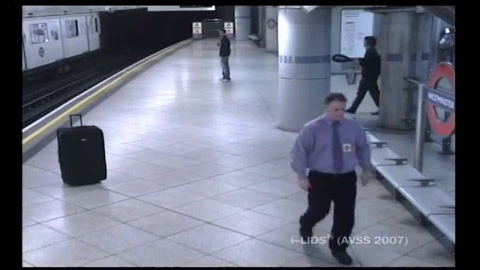

A man in a purple shirt and dark trousers walks across a tiled subway platform, passing a stationary black suitcase near the edge of the train tracks. In the background, other passengers are visible near pillars and glass barriers, with a white train stopped on the left side of the platform.  
On-screen text reads: "FLDS (AVSS 2007)"

(7.7 s)


In [17]:
from PIL import Image, ImageDraw

IMAGE_PATH = "/kaggle/input/datasets/amrwahidi5180/vlm-dataset/hqdefault.jpg"   # <- change to a real frame from your dataset

if not os.path.exists(IMAGE_PATH):
    # Fallback test image: a dark "camera frame" with a timestamp, a person-like figure and a red box.
    IMAGE_PATH = "/kaggle/working/test_frame.jpg"
    img = Image.new("RGB", (640, 360), (40, 40, 48))
    d = ImageDraw.Draw(img)
    d.text((12, 10), "CAM 2   2026-10-12 21:45:03", fill=(255, 255, 255))
    d.ellipse((300, 120, 340, 160), fill=(220, 180, 150))      # head
    d.rectangle((295, 160, 345, 260), fill=(30, 90, 200))      # body (blue shirt)
    d.rectangle((420, 220, 480, 270), fill=(200, 30, 30))      # red box on the floor
    img.save(IMAGE_PATH)
    print("No frame found, using a generated test image:", IMAGE_PATH)

display(Image.open(IMAGE_PATH).resize((480, 270)))

answer, seconds = ask(
    "Describe this surveillance frame in 2 sentences. "
    "Then read any on-screen text (camera name, timestamp) exactly as written.",
    image_paths=[IMAGE_PATH],
)
print(answer)
print(f"\n({seconds:.1f} s)")

## 9. (Optional) Stop the server to free the GPUs

In [18]:
ollama_process.terminate()   # stops the background server started in step 3
log_file.close()
print("Ollama server stopped. Re-run step 3 to start it again.")

Ollama server stopped. Re-run step 3 to start it again.
